In [7]:
import re
from urllib.parse import urlparse, parse_qs

_ipv4_re = re.compile(r"^(?:\d{1,3}\.){3}\d{1,3}$")
_shorteners = {"bit.ly","tinyurl.com","t.co","goo.gl","ow.ly","is.gd","buff.ly","rb.gy","cutt.ly"}
_suspicious_tokens = ["login","verify","update","secure","account","bank","signin","confirm","password","webscr","wp-","admin","support","billing"]

def url_features(url: str) -> dict:
    u_raw = "" if url is None else str(url).strip()
    u_lower = u_raw.lower()

    u_for_parse = ("http://" + u_raw) if (u_raw != "" and "://" not in u_raw) else u_raw
    p = urlparse(u_for_parse)

    scheme = (p.scheme or "").lower()
    host = (p.hostname or "").lower()
    netloc_raw = (p.netloc or "").lower()
    path = p.path or ""
    query = p.query or ""
    fragment = p.fragment or ""

    feats = {}
    feats["url_len"] = len(u_raw)
    feats["host_len"] = len(host)
    feats["path_len"] = len(path)
    feats["query_len"] = len(query)
    feats["frag_len"] = len(fragment)

    feats["count_dot"] = u_raw.count(".")
    feats["count_hyphen"] = u_raw.count("-")
    feats["count_at"] = u_raw.count("@")
    feats["count_qmark"] = u_raw.count("?")
    feats["count_equal"] = u_raw.count("=")
    feats["count_amp"] = u_raw.count("&")
    feats["count_percent"] = u_raw.count("%")
    feats["count_underscore"] = u_raw.count("_")
    feats["count_slash"] = u_raw.count("/")
    feats["count_colon"] = u_raw.count(":")
    feats["count_semicolon"] = u_raw.count(";")

    digits = sum(ch.isdigit() for ch in u_raw)
    feats["count_digit"] = digits
    feats["digit_ratio"] = (digits / len(u_raw)) if len(u_raw) > 0 else 0.0

    host_parts = [x for x in host.split(".") if x] if host else []
    feats["host_dot"] = host.count(".") if host else 0
    feats["subdomain_count"] = max(0, len(host_parts) - 2) if len(host_parts) >= 2 else 0
    feats["tld_len"] = len(host_parts[-1]) if len(host_parts) >= 1 else 0

    feats["is_https"] = 1 if scheme == "https" else 0
    feats["has_ip"] = 1 if (host != "" and _ipv4_re.match(host) is not None) else 0
    feats["is_shortener"] = 1 if host in _shorteners else 0
    feats["has_port"] = 1 if (p.port is not None) else 0
    feats["has_userinfo"] = 1 if ("@" in netloc_raw) else 0

    path_segments = [seg for seg in path.split("/") if seg]
    feats["path_depth"] = len(path_segments)

    qs = parse_qs(query, keep_blank_values=True)
    feats["num_params"] = len(qs)
    feats["num_unique_params"] = len(qs.keys())

    if len(qs) > 0:
        keys = list(qs.keys())
        vals = [v for vs in qs.values() for v in vs]
        feats["param_key_avg_len"] = (sum(len(k) for k in keys) / len(keys)) if len(keys) else 0.0
        feats["param_val_avg_len"] = (sum(len(v) for v in vals) / len(vals)) if len(vals) else 0.0
    else:
        feats["param_key_avg_len"] = 0.0
        feats["param_val_avg_len"] = 0.0

    feats["suspicious_token_count"] = sum(1 for t in _suspicious_tokens if t in u_lower)

    return feats

In [9]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay

import matplotlib.pyplot as plt
from IPython.display import display

In [11]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

path = root / "data" / "processed" / "balanced_1000_1000_000_003.csv"
raw = pd.read_csv(path)

cols = {c.lower(): c for c in raw.columns}
def pick(*names):
    for n in names:
        if n.lower() in cols:
            return cols[n.lower()]
    return None

col_url = pick("url")
col_label = pick("label")
col_sha = pick("sha256", "phreshphish_sha256")

use_cols = [c for c in [col_sha, col_url, col_label] if c is not None]
df = raw[use_cols].copy()

if col_sha is not None and col_sha != "sha256":
    df.rename(columns={col_sha: "sha256"}, inplace=True)
if col_url is not None and col_url != "url":
    df.rename(columns={col_url: "url"}, inplace=True)
if col_label is not None and col_label != "label":
    df.rename(columns={col_label: "label"}, inplace=True)

df.head()

,sha256,url,label
0,6a2a750bc03304b025b66066217f9e0b0e53f18dcd1ed3...,https://www.dijugratas.hu/,benign
1,70c9ed42fcccb424ebbb38607199b2d569bc3d66b020d9...,https://axp.schoolsay.shop/,phish
2,e9749c745f458a49173d528a0128968f4097c121dd2bac...,https://www.luggagefactory.com/collections/sam...,benign
3,dd6e546a92595017557f268dd1369bb2ed70addfdc35ae...,https://help-cdn-ledger---live.webflow.io/,phish
4,ad3f076b62b3257ecd927a2352018ae812b1039d1cdf96...,https://www.vatcalculators.online/au-gst-calcu...,benign


In [12]:
s = df["label"].astype(str).str.lower().str.strip()
df["y"] = s.map({"benign": 0, "phish": 1})
df = df.dropna(subset=["url", "y"]).copy()
df["y"] = df["y"].astype(int)
df["y"].value_counts()

y
0    1000
1    1000
Name: count, dtype: int64

In [13]:
feat = df["url"].apply(url_features).apply(pd.Series)

base_cols = ["sha256", "url", "label", "y"] if "sha256" in df.columns else ["url", "label", "y"]
features_url = pd.concat([df[base_cols].reset_index(drop=True), feat.reset_index(drop=True)], axis=1)

features_url.shape

(2000, 36)

In [14]:
from pathlib import Path

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

out_path = root / "data" / "processed" / "features_url_1000_1000_000_003.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)

features_url.to_csv(out_path, index=False)
str(out_path)

'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\features_url_1000_1000_000_003.csv'

In [15]:
drop_cols = [c for c in ["sha256", "url", "label", "y"] if c in features_url.columns]
X = features_url.drop(columns=drop_cols)
y = features_url["y"].astype(int)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((1600, 32), (400, 32))

[[171  29]
 [ 32 168]]
              precision    recall  f1-score   support

           0     0.8424    0.8550    0.8486       200
           1     0.8528    0.8400    0.8463       200

    accuracy                         0.8475       400
   macro avg     0.8476    0.8475    0.8475       400
weighted avg     0.8476    0.8475    0.8475       400

0.9373499999999999


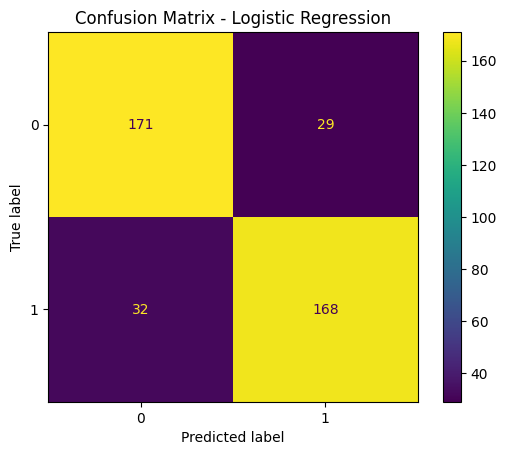

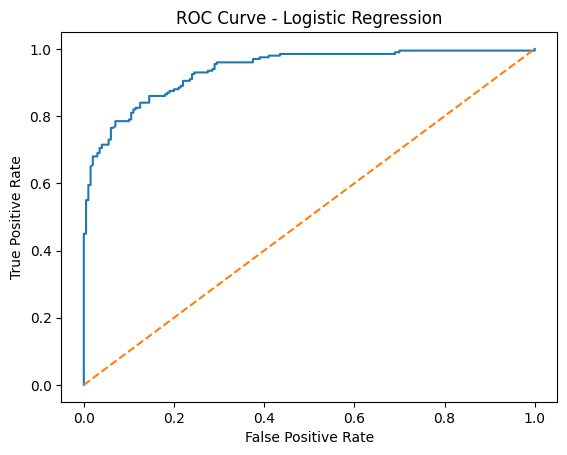

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000))
])

lr.fit(X_train, y_train)

y_prob = lr.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))
print(roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.show()

[[187  13]
 [ 26 174]]
              precision    recall  f1-score   support

           0     0.8779    0.9350    0.9056       200
           1     0.9305    0.8700    0.8992       200

    accuracy                         0.9025       400
   macro avg     0.9042    0.9025    0.9024       400
weighted avg     0.9042    0.9025    0.9024       400

0.9677375


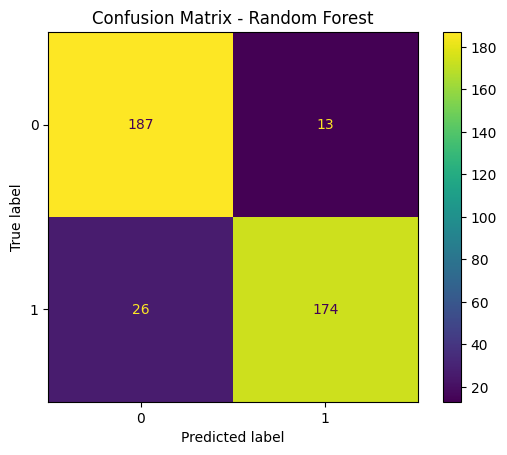

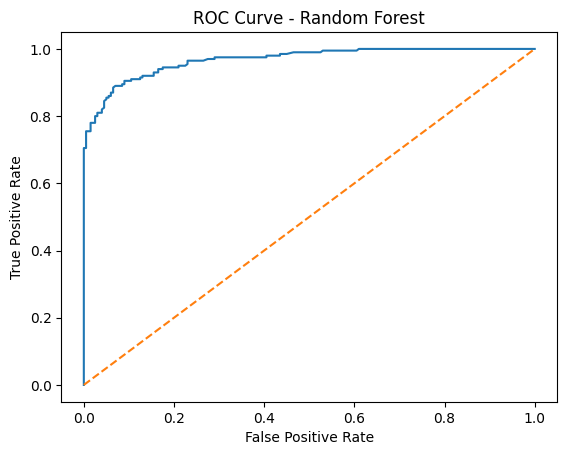

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_prob = rf.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))
print(roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Random Forest")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.show()

In [18]:
try:
    import xgboost as xgb
except ImportError:
    !pip -q install xgboost
    import xgboost as xgb

[[184  16]
 [ 25 175]]
              precision    recall  f1-score   support

           0     0.8804    0.9200    0.8998       200
           1     0.9162    0.8750    0.8951       200

    accuracy                         0.8975       400
   macro avg     0.8983    0.8975    0.8974       400
weighted avg     0.8983    0.8975    0.8974       400

0.964975


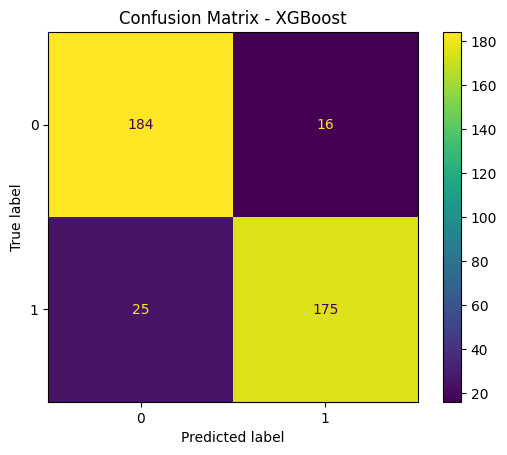

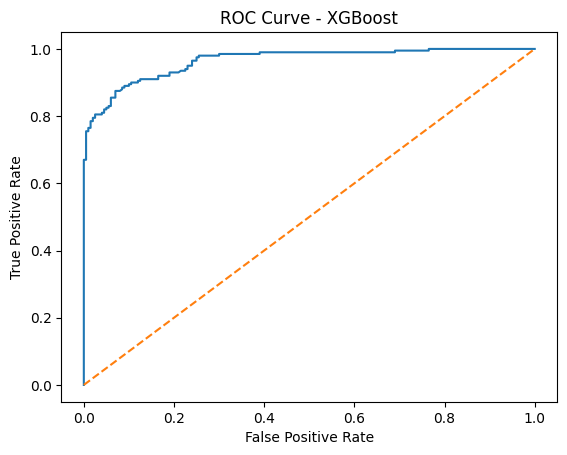

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

xgb_model = xgb.XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    min_child_weight=1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(X_train, y_train)

y_prob = xgb_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))
print(roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - XGBoost")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.show()

In [20]:
rows = []

for name, model in [("LogReg", lr), ("RF", rf), ("XGBoost", xgb_model)]:
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    rows.append({
        "model": name,
        "roc_auc": float(auc),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1])
    })

metrics_df = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
metrics_df

,model,roc_auc,tn,fp,fn,tp
0,RF,0.967738,187,13,26,174
1,XGBoost,0.964975,184,16,25,175
2,LogReg,0.937350,171,29,32,168


In [21]:
best_name = metrics_df.loc[0, "model"]
best_model = {"LogReg": lr, "RF": rf, "XGBoost": xgb_model}[best_name]

y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

view = features_url.loc[X_test.index, ["url", "label", "y"]].copy()
view["pred"] = y_pred
view["proba"] = y_prob

fp_df = view[(view["y"] == 0) & (view["pred"] == 1)].sort_values("proba", ascending=False)
fn_df = view[(view["y"] == 1) & (view["pred"] == 0)].sort_values("proba", ascending=True)

best_name

'RF'

In [22]:
from IPython.display import display

display(fp_df.head(20))
display(fn_df.head(20))

,url,label,y,pred,proba
1323,https://allaccess.therapeuticresearch.com/,benign,0,1,0.859495
1586,https://jonassoftware.com/our-companies,benign,0,1,0.768000
1500,https://trajectoire.sante-ra.fr/trajectoire/de...,benign,0,1,0.750000
192,https://www.awajishima-kanko.jp/modelcourse/,benign,0,1,0.719667
99,https://www.foxnews.com/video/6362198807112,benign,0,1,0.710000
1030,https://pcm.annas-archive.org/,benign,0,1,0.691821
215,https://catholicsaints.info/,benign,0,1,0.673333
82,https://minkabu.jp/stock/7042,benign,0,1,0.668000
921,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.634000
1064,https://linktr.ee/PoppyPlaytimeCo,benign,0,1,0.582000


,url,label,y,pred,proba
51,https://multiswiftchain.web.app/,phish,1,0,0.040983
1603,https://elffetish.com/tunnel/email-template.html,phish,1,0,0.058000
1302,https://sirius-agency.com/source/policy.html,phish,1,0,0.084000
154,https://aktiondb.com/,phish,1,0,0.089238
256,https://apozzwn.smitvisualsupplies.com/,phish,1,0,0.103767
552,https://www.whatsappxs.top/asw,phish,1,0,0.169960
448,https://cooperativasicoob.com/acesso/,phish,1,0,0.190000
266,https://glossvita.com/cart/checkout,phish,1,0,0.220000
416,https://www.powr.io/media-gallery/i/39114908#page,phish,1,0,0.220000
1790,https://in-whatsapps.com/index.php,phish,1,0,0.222000


In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}

models = {"LogReg": lr, "RF": rf, "XGBoost": xgb_model}

cv_rows = []
for name, m in models.items():
    out = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "model": name,
        "f1_mean": float(np.mean(out["test_f1"])),
        "f1_std": float(np.std(out["test_f1"])),
        "auc_mean": float(np.mean(out["test_roc_auc"])),
        "auc_std": float(np.std(out["test_roc_auc"])),
        "acc_mean": float(np.mean(out["test_accuracy"])),
        "acc_std": float(np.std(out["test_accuracy"]))
    })

cv_df = pd.DataFrame(cv_rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
cv_df

,model,f1_mean,f1_std,auc_mean,auc_std,acc_mean,acc_std
0,XGBoost,0.883856,0.010814,0.961015,0.006405,0.8850,0.011511
1,RF,0.891304,0.015680,0.960127,0.009966,0.8935,0.017000
2,LogReg,0.844643,0.016083,0.924995,0.011903,0.8425,0.018097


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

feat_names = X.columns.tolist()

rf_imp = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False)
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feat_names).sort_values(ascending=False)

top_n = 20
rf_top = rf_imp.head(top_n).reset_index()
rf_top.columns = ["feature", "importance"]

xgb_top = xgb_imp.head(top_n).reset_index()
xgb_top.columns = ["feature", "importance"]

rf_top

,feature,importance
0,path_len,0.160049
1,host_len,0.124826
2,count_slash,0.122879
3,url_len,0.107149
4,path_depth,0.105253
5,tld_len,0.096900
6,count_hyphen,0.039909
7,digit_ratio,0.038161
8,count_digit,0.032548
9,is_https,0.032355


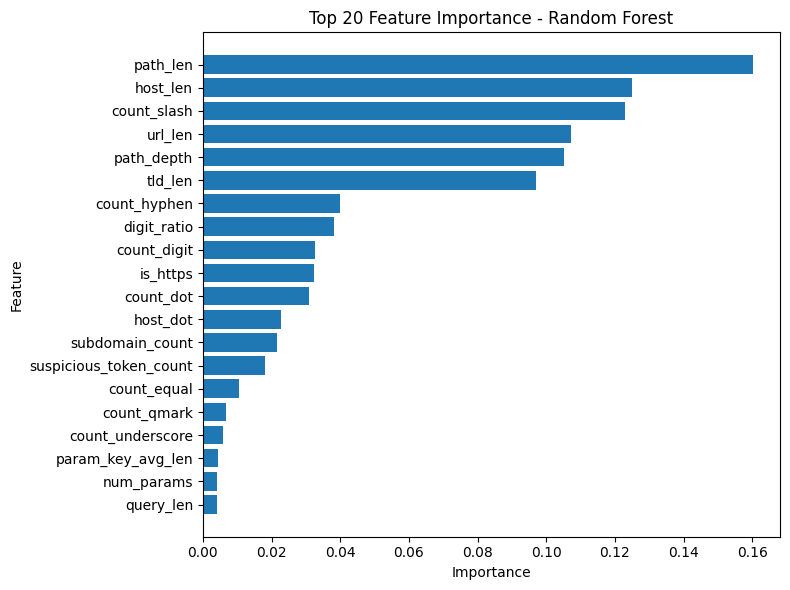

,feature,importance
0,count_qmark,0.279581
1,query_len,0.160404
2,count_slash,0.093622
3,count_amp,0.067269
4,count_equal,0.061895
5,is_https,0.049056
6,tld_len,0.035420
7,path_len,0.034008
8,host_dot,0.029194
9,suspicious_token_count,0.024038


In [25]:
plt.figure(figsize=(8, 6))
plt.barh(rf_top["feature"][::-1], rf_top["importance"][::-1])
plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

xgb_top

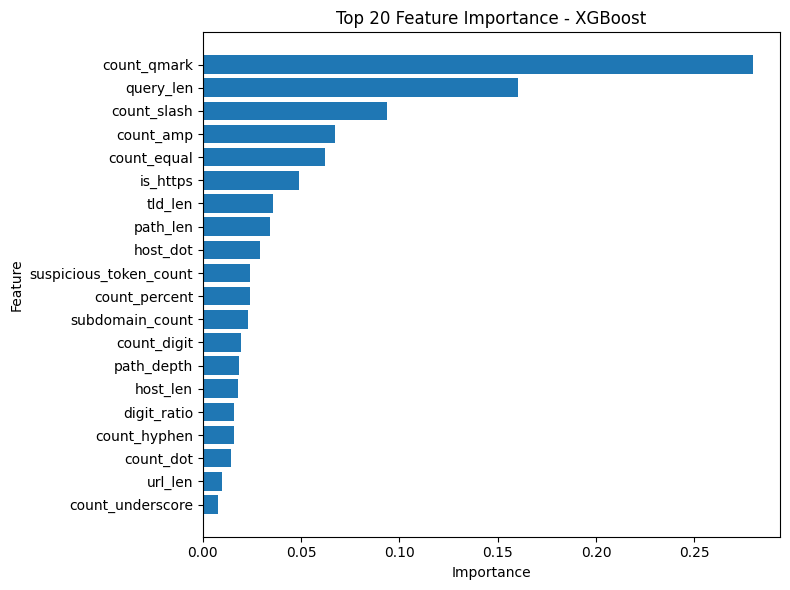

In [26]:
plt.figure(figsize=(8, 6))
plt.barh(xgb_top["feature"][::-1], xgb_top["importance"][::-1])
plt.title("Top 20 Feature Importance - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

d:\anaconda\envs\py311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


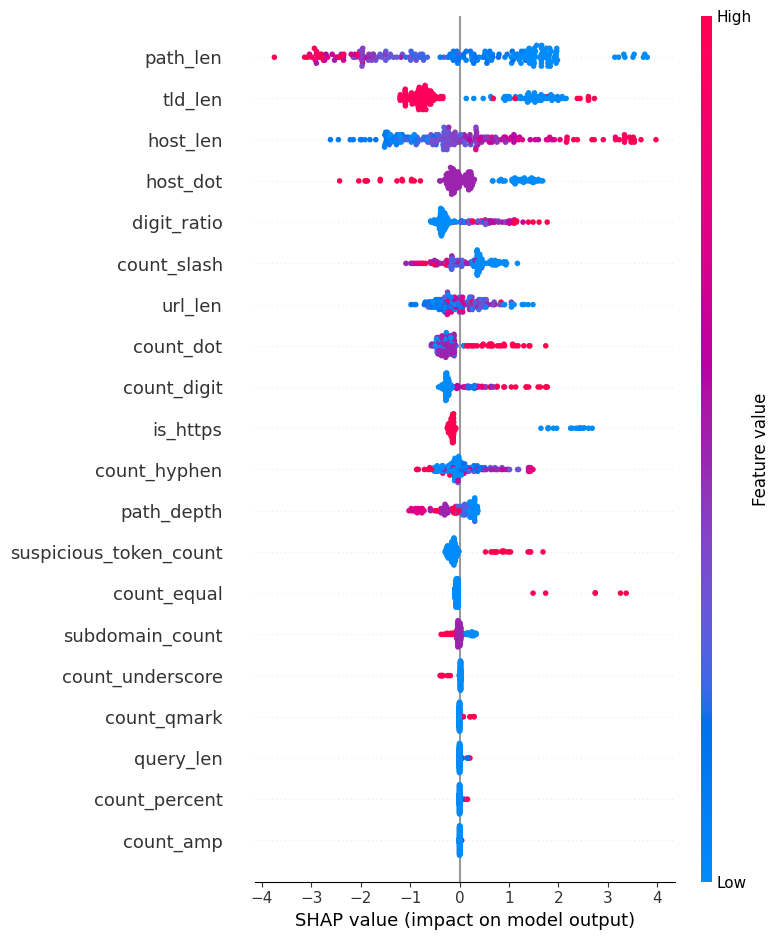

In [27]:
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

import matplotlib.pyplot as plt

X_sample = X_test.sample(n=min(200, len(X_test)), random_state=42)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

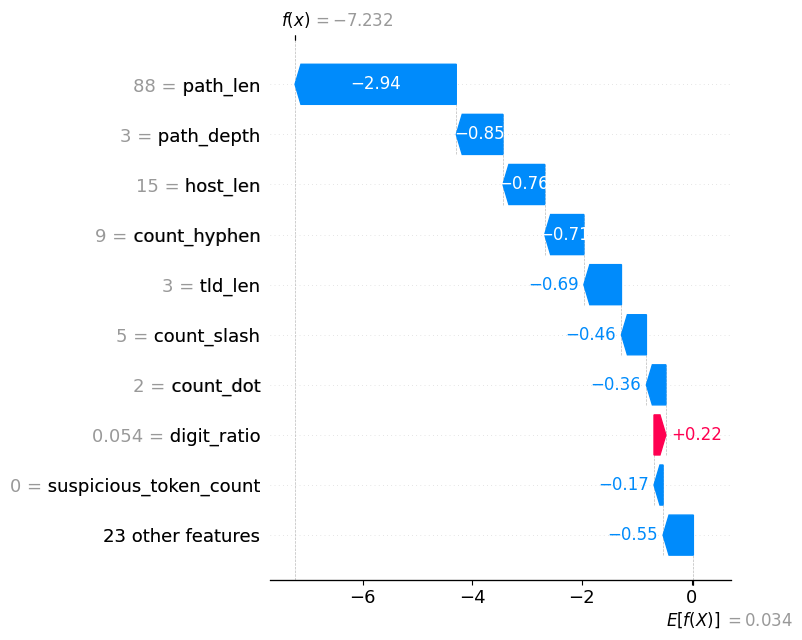

In [28]:
idx = X_test.index[0]
x_one = X_test.loc[[idx]]

explainer = shap.TreeExplainer(xgb_model)
sv = explainer.shap_values(x_one)

shap.waterfall_plot(shap.Explanation(values=sv[0], base_values=explainer.expected_value, data=x_one.iloc[0], feature_names=x_one.columns), show=False)
plt.tight_layout()
plt.show()

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

rf_opt = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
rf_opt.fit(X_tr, y_tr)

val_prob = rf_opt.predict_proba(X_val)[:, 1]
p, r, th = precision_recall_curve(y_val, val_prob)

p2, r2 = p[1:], r[1:]
f1 = (2 * p2 * r2) / (p2 + r2 + 1e-12)
best_i = int(np.argmax(f1))
best_th = float(th[best_i])

rf_final = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
rf_final.fit(X_train, y_train)

test_prob = rf_final.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_th).astype(int)

best_th, roc_auc_score(y_test, test_prob), confusion_matrix(y_test, test_pred)

(0.516,
 0.9677375,
 array([[189,  11],
        [ 28, 172]]))

              precision    recall  f1-score   support

           0     0.8710    0.9450    0.9065       200
           1     0.9399    0.8600    0.8982       200

    accuracy                         0.9025       400
   macro avg     0.9054    0.9025    0.9023       400
weighted avg     0.9054    0.9025    0.9023       400



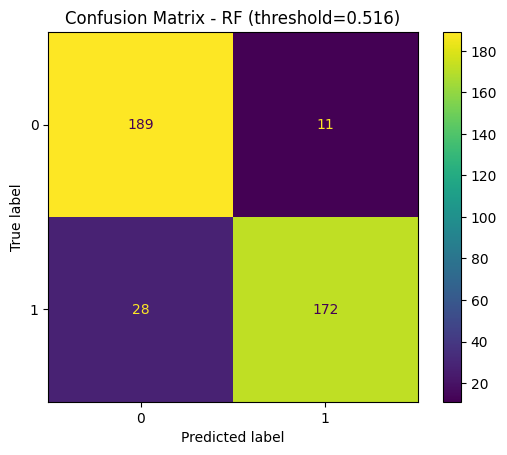

In [30]:
print(classification_report(y_test, test_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title(f"Confusion Matrix - RF (threshold={best_th:.3f})")
plt.show()

In [31]:
view_th = features_url.loc[X_test.index, ["url", "label", "y"]].copy()
view_th["pred"] = test_pred
view_th["proba"] = test_prob

fp_df_th = view_th[(view_th["y"] == 0) & (view_th["pred"] == 1)].sort_values("proba", ascending=False)
fn_df_th = view_th[(view_th["y"] == 1) & (view_th["pred"] == 0)].sort_values("proba", ascending=True)

display(fp_df_th.head(20))
display(fn_df_th.head(20))

,url,label,y,pred,proba
1323,https://allaccess.therapeuticresearch.com/,benign,0,1,0.859495
1586,https://jonassoftware.com/our-companies,benign,0,1,0.768000
1500,https://trajectoire.sante-ra.fr/trajectoire/de...,benign,0,1,0.750000
192,https://www.awajishima-kanko.jp/modelcourse/,benign,0,1,0.719667
99,https://www.foxnews.com/video/6362198807112,benign,0,1,0.710000
1030,https://pcm.annas-archive.org/,benign,0,1,0.691821
215,https://catholicsaints.info/,benign,0,1,0.673333
82,https://minkabu.jp/stock/7042,benign,0,1,0.668000
921,https://web.snelstart.nl/ef30ad51-7bf5-4f6f-ba...,benign,0,1,0.634000
1064,https://linktr.ee/PoppyPlaytimeCo,benign,0,1,0.582000


,url,label,y,pred,proba
51,https://multiswiftchain.web.app/,phish,1,0,0.040983
1603,https://elffetish.com/tunnel/email-template.html,phish,1,0,0.058000
1302,https://sirius-agency.com/source/policy.html,phish,1,0,0.084000
154,https://aktiondb.com/,phish,1,0,0.089238
256,https://apozzwn.smitvisualsupplies.com/,phish,1,0,0.103767
552,https://www.whatsappxs.top/asw,phish,1,0,0.169960
448,https://cooperativasicoob.com/acesso/,phish,1,0,0.190000
266,https://glossvita.com/cart/checkout,phish,1,0,0.220000
416,https://www.powr.io/media-gallery/i/39114908#page,phish,1,0,0.220000
1790,https://in-whatsapps.com/index.php,phish,1,0,0.222000


In [32]:
rf_th_row = {
    "model": "RF(threshold)",
    "roc_auc": float(roc_auc_score(y_test, test_prob)),
    "tn": int(confusion_matrix(y_test, test_pred)[0, 0]),
    "fp": int(confusion_matrix(y_test, test_pred)[0, 1]),
    "fn": int(confusion_matrix(y_test, test_pred)[1, 0]),
    "tp": int(confusion_matrix(y_test, test_pred)[1, 1]),
    "threshold": float(best_th)
}

metrics_df2 = pd.concat([metrics_df, pd.DataFrame([rf_th_row])], ignore_index=True)
metrics_df2

,model,roc_auc,tn,fp,fn,tp,threshold
0,RF,0.967738,187,13,26,174,NaN
1,XGBoost,0.964975,184,16,25,175,NaN
2,LogReg,0.937350,171,29,32,168,NaN
3,RF(threshold),0.967738,189,11,28,172,0.516


In [33]:
from pathlib import Path

root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

report_dir = root / "data" / "processed" / "report_tables"
report_dir.mkdir(parents=True, exist_ok=True)

metrics_df2.to_csv(report_dir / "url_metrics_testset.csv", index=False)
cv_df.to_csv(report_dir / "url_metrics_cv5.csv", index=False)
rf_top.to_csv(report_dir / "url_rf_top20_features.csv", index=False)
xgb_top.to_csv(report_dir / "url_xgb_top20_features.csv", index=False)

str(report_dir)

'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables'

In [34]:
fp_df_th.head(50).to_csv(report_dir / "url_fp_top50.csv", index=False)
fn_df_th.head(50).to_csv(report_dir / "url_fn_top50.csv", index=False)

("saved", str(report_dir / "url_fp_top50.csv"), str(report_dir / "url_fn_top50.csv"))

('saved',
 'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables\\url_fp_top50.csv',
 'c:\\Users\\14176\\Desktop\\Honours Project\\Hons Project\\data\\processed\\report_tables\\url_fn_top50.csv')